# The Emergence of Protobits

NicDeclic  
2026-10-29

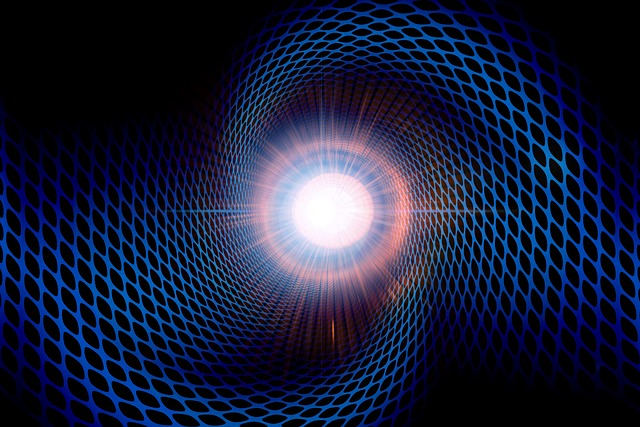

> *“To create is not to add. It is to strip away the noise, the fear,
> the walls.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

Now that the structural alphabet of our molecular processor is complete,
it is time to unleash its true computational potential.

Yet, the moment we begin pushing these carbon networks, an astonishing
realization strikes: **we are no longer playing by the established rules
of “textbook” quantum computing.**

Mainstream quantum architectures (such as transmon qubits, trapped ions,
or photonic circuits) operate within a rigid, sequential paradigm:  
\* You initialize a discrete register of isolated qubits,  
\* You apply a unidirectional, clock-driven cascade of discrete unitary
logic gates ($U_1, U_2, \dots, U_n$),  
\* And you collapse the state through projective measurement at the very
end.

Our conjugated carbon networks dismantle these constraints. Because
computation is embodied in a continuous, delocalized electron cloud
($\pi$-resonance) anchored in a physical molecular graph, phenomena
emerge that have no equivalent in classical or standard quantum models.

Chief among these anomalies is the intrinsic ability to **compute
backwards.**

------------------------------------------------------------------------

------------------------------------------------------------------------

## Reverse Computing

One of the most extraordinary properties of conjugated molecular
networks is that they possess **no intrinsic, hardwired notion of
“inputs” or “outputs.”**

A chemical bond is simply a physical degree of freedom. It is strictly
the observer who chooses to designate certain peripheral bonds as
“inputs” (where boundary constraints are imposed) and others as
“outputs” (where the resulting state is read).

Consequently, **there is zero difference in computational time between
evaluating a function forward or inverting it backward.**

For a computer scientist accustomed to classical, sequential algorithmic
complexity—where multiplying two numbers takes microseconds while
factoring them can take millennia—this realization is deeply
counterintuitive, almost disorienting.

### Physical Compute Time: Bounded by Molecular Diameter

In an algorithmic circuit, execution time scales with the depth of the
gate cascade ($O(\text{depth})$).

In a molecular network, however, computation is not an execution loop;
it is a **physical wave relaxation process**. The entire $\pi$-electron
cloud redistributes collectively across the carbon framework.

Therefore, the computational time ($t_{\text{compute}}$) is physically
bounded strictly by the **effective spatial diameter ($D$) of the
molecular graph** divided by the Fermi velocity of the $\pi$-electrons
($v_F \approx 10^6\ \text{m/s}$):

$$t_{\text{compute}} \approx \frac{D}{v_F}$$

Across a molecular processor spanning tens of nanometers, this
relaxation settles on the scale of **femtoseconds
($10^{-15}\ \text{s}$)**—whether computing forward or backward. The
arrow of computational complexity dissolves into geometric boundary
relaxation.

------------------------------------------------------------------------

### Inverting the “Letter Envelope”

Let us ground this principle in our familiar “Letter Envelope” molecule.

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Letter Envelope")

# Add atoms
c1 = mol.add_atom(x=-0.8, y=0.5)
c2 = mol.add_atom(x=0.8, y=0.5)
c3 = mol.add_atom(x=-0.3, y=0)
c4 = mol.add_atom(x=0.3, y=0)
c5 = mol.add_atom(x=-0.8, y=-0.5)
c6 = mol.add_atom(x=0.8, y=-0.5)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single", label="A")
b2 = mol.add_bond(c1, c5, order="single")
b3 = mol.add_bond(c2, c6, order="single")
b4 = mol.add_bond(c1, c3, order="single")
b5 = mol.add_bond(c2, c4, order="single")
b6 = mol.add_bond(c3, c4, order="single", label="C")
b7 = mol.add_bond(c3, c5, order="single")
b8 = mol.add_bond(c4, c6, order="single")
b9 = mol.add_bond(c5, c6, order="single", label="B")

mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>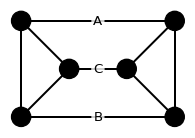</p>
</div></td>
</tr>
</tbody>
</table>

Earlier, we treated bonds $A$ and $B$ as inputs and bond $C$ as the XNOR
output. Now, let us deliberately flip the roles:  
1. We clamp the former output bond **$C$ to state “1”** (imposing this
as our boundary condition).  
2. We step back and observe the resulting states at the former input
bonds $A$ and $B$.

``` python
b6.role="input"
b6.state_type="fixed"
b6.order="double"

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>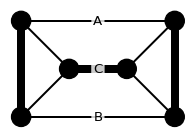</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p>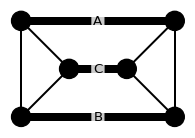</p>
</div></td>
</tr>
</tbody>
</table>

What emerges at the terminals $A$ and $B$ is an exact **coherent
superposition** of all valid input combinations that satisfy the
condition $C = 1$:

``` python
bs1="00"
bs2="11"

r1 = TransitionMatrix.from_bitstring(bs1)
r2 = TransitionMatrix.from_bitstring(bs2)

r3 = r1 + r2

r4 = r3.normalize()

display_inline("A", r"\otimes", "B", "=", r"\Big\{", quote_latex(bs1), "+", quote_latex(bs2), r"\Big\}")

display_inline(r"\Rightarrow", "A", r"\otimes", "B", "=", r"\Big\{", r1.to_katex(), "+", r2.to_katex(), r"\Big\}")

display_inline(r"\Rightarrow", "A", r"\otimes", "B", "=", r"\Big\{", r3.to_katex(), r"\Big\}")

display_inline(r"\Rightarrow", "A", r"\otimes", "B", "=", r4.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span
class="math display"><em>A</em> ⊗ <em>B</em> = {“00” + “11”}</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \Rightarrow A \otimes B =
\Big\{  \begin{array}{|cccc|}  \hline 1 &amp; 0 &amp; 0 &amp; 0
\\  \hline \end{array}  +  \begin{array}{|cccc|}  \hline 0 &amp; 0 &amp;
0 &amp; 1 \\  \hline \end{array}  \Big\} $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \Rightarrow A \otimes B =
\Big\{  \begin{array}{|cccc|}  \hline 1 &amp; 0 &amp; 0 &amp; 1
\\  \hline \end{array}  \Big\} $$</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \Rightarrow A \otimes B
=  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline ~ &amp;
0.5 &amp; 0 &amp; 0 &amp; 0.5 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

The molecule does not perform trial-and-error backtracking. The carbon
network natively filters out all inconsistent configurations (“01” and
“10”), letting only the valid solution manifold resonate.

------------------------------------------------------------------------

### Measurement as a Topological Filter

This requires us to fundamentally redefine what a “measurement” means in
molecular computing:

In standard textbook quantum computing, measurement is modeled as a
destructive, projective von Neumann collapse. You roll a quantum die,
hope you sample the right outcome, and repeat the experiment thousands
of times (shots) to reconstruct a probability distribution.

In our molecular architecture, **measurement is not a lottery; it is a
resonant boundary filter.**

Much like acoustic standing waves in an organ pipe:  
\* Clamping the output terminal is equivalent to closing or opening the
pipe’s acoustic boundaries.  
\* The wave equation inside the carbon cavity cannot sustain frequencies
or configurations that violate these physical boundary conditions.  
\* The wrong answers are not “sampled and discarded probabilistically”;
**they are physically prohibited from existing as stationary modes
within the cavity.**

The correct input states emerge directly as the only allowed harmonic
modes of the molecule.

------------------------------------------------------------------------

### The Verdict: Carbon Bonds Are Not Qubits

This marks the definitive departure from the conventional quantum
paradigm:

- A standard quantum circuit requires a growing overhead of **ancillary
  qubits** and complex uncomputation cycles to reverse a non-bijective
  gate without violating unitarity.  
- A standard quantum circuit suffers from probabilistic measurement
  misses, requiring iterative amplitude amplification (such as Grover’s
  algorithm).

Our carbon-carbon bonds require zero ancillary overhead and eliminate
the probabilistic lottery through boundary-condition filtering.

The conclusion is inescapable: **conjugated carbon bonds are not
qubits.**

------------------------------------------------------------------------

## Protobits: The Fundamental Substrate of Information

Up to this point, we have formulated the states of our carbon bonds
using the language of **p-bits** (probabilistic bits). While
mathematically useful, this probabilistic framing captures only a
fraction of their true physical capability.

In modern spintronics, classical p-bits are used to construct what
researchers call a *“poor man’s quantum computer”*—stochastic hardware
capable of sampling complex probability distributions and performing
simulated annealing, but fundamentally lacking genuine **quantum
superposition** and **entanglement**.

Conjugated carbon bonds, however, are inherently quantum-mechanical
entities. Their delocalized $\pi$-electron clouds routinely support true
quantum superposition (resonance) and macroscopic entanglement across
the molecular framework.

### Qubits as a Sub-Phenomenon

Because our molecular architecture achieves universal logic, it is
entirely possible to construct arithmetic hardware—multipliers and
adders—purely out of conjugated carbon gates.

Using this capability, one could build a full processing unit from
carbon molecules, executing binary arithmetic to multiply **complex
floating-point matrices** just like a classical supercomputer simulating
quantum mechanics.

However, there is a fundamental architectural distinction in how the
computation is handled:

On a classical supercomputer, simulating $N$ qubits forces the software
to construct and multiply monolithic, global matrices that scale
**exponentially** ($2^N \times 2^N$) via massive tensor products,
rapidly exhausting memory.

In our molecular architecture, we avoid this exponential memory
explosion entirely. Because the logic is physically mapped across the
carbon network, the hardware only ever computes with **small,
constant-sized matrices circuits corresponding strictly to the local
logic gates** involved. The physical wiring of the molecular circuit
naturally routes the states superpositions without requiring an
exponentially bloated global matrix.

Measuring the terminal registers at the end of these complex
matrix-multiplication circuits yields the exact statistical
distributions of textbook quantum mechanics.

To be sure, assembling millions of molecular gates just to crunch
floating-point complex numbers is an absurdly inefficient way to
implement a qubit. Yet, it serves as a rigorous **theoretical existence
proof**:

Because conjugated carbon bonds can build the machinery to simulate
complex quantum state vectors, **carbon-carbon bonds natively encompass
all computational capabilities of qubits.**

In fact, as we will demonstrate in an upcoming post, the minimal
physical threshold required to natively synthesize a single, fully
coherent quantum qubit is **exactly 3 conjugated carbon-carbon bonds.**

### The Hierarchy of Information: A True Superset

This leads us to a profound theoretical separation:  
\* A standard qubit **cannot** emulate a bidirectional conjugated carbon
bond without an unbounded overhead of ancillary registers and loss of
spatial invariance.  
\* A network of conjugated carbon bonds **can** natively emulate a
qubit.

In computational complexity theory, when system $A$ can simulate system
$B$, but system $B$ cannot simulate system $A$ under bounded resources,
it establishes that **$A$ is a strict superset of $B$.**

$$\text{Conjugated carbon bonds (Protobits) } \supset \text{ Qubits } \supset \text{ p-bits } \supset \text{ Classical Bits}$$

Step back and look at the grand architectural portrait of information
that emerges:  
1. **At the fundamental layer:** Conjugated carbon bonds operate as
native quantum primitives.  
2. **Coherent aggregation:** Grouping 3 coupled carbon bonds synthesizes
a textbook **Qubit** (in the $\mathbb{C}^2$ state space).  
3. **Decoherence:** When a carbon bond loses its quantum phase coherence
to environmental thermal noise, it gracefully degrades into a **p-bit**
(probabilistic bit).  
4. **Measurement / Clamping:** When a p-bit or a qubit is projected
through a macroscopic boundary measurement, it collapses into a
deterministic **Classical Bit** ($0$ or $1$).

Do you see the relationship?

Conjugated carbon bonds are the generative root at the base of the
entire hierarchy. They are the physical engine from which all other
forms of computation naturally emerge.

For this reason, we introduce this new primitive to the scientific
lexicon as the **“Protobit”**—from the Greek *proto-* (first, primitive,
original) and *bit* (binary unit).

The Protobit is the physical ancestor of digital and quantum information
alike.

------------------------------------------------------------------------

## Why Not Dirac Notation?

Readers familiar with quantum literature might find it surprising that
**Dirac’s bra-ket notation
($\langle \psi | \text{ and } | \psi \rangle$) is intentionally absent
throughout this work.**

This is a deliberate architectural and pedagogical choice, driven by
several practical reasons:

- **Protobits Are Not Qubits:** Dirac notation was tailored for isolated
  state vectors in Hilbert space ($\mathbb{C}^2$). While one could
  technically bend and stretch the bra-ket formalism to fit protobits,
  standard matrix and set algebra already handles the molecular
  transition networks flawlessly. In fact, standard linear algebra is
  more compact, visually transparent, and universally understood across
  scientific disciplines.  
- **The “Right-to-Left” Cognitive Tax:** Standard quantum mechanics
  writes operators acting on kets from right to left ($U |\psi\rangle$),
  while physical circuits and computer algorithms are read strictly from
  **left to right** (Input $\rightarrow$ Gate $\rightarrow$ Output).
  This inverted convention adds a needless layer of mental gymnastics
  when translating a visual graph into a formal equation. While there is
  no universal law governing writing direction, we should at least align
  our algebraic syntax with the visual flow of our physical circuit
  diagrams.  
- **Finite Molecular Graphs vs. Infinite Dimensions:** Dirac’s bra-ket
  formalism was historically engineered to bridge discrete states with
  infinite-dimensional, continuous Hilbert spaces (such as position
  wavefunctions $\psi(x)$). In our framework, we operate strictly over
  finite, discrete networks of carbon bonds spanning well-defined
  $2^M \times 2^N$ configuration spaces. We have no practical need for
  Schrödinger’s infinite-dimensional apparatus when compact,
  finite-dimensional matrix algebra models the discrete topology with
  far greater precision.  
- **The Multi-Product Dilemma:** In our Conjugated Carbon
  Computing (CCC) framework, three distinct matrix operations are used
  on an equal footing: standard matrix dot product ($\cdot$), Kronecker
  tensor product ($\otimes$), and element-wise Hadamard product
  ($\odot$). Why privilege one specific multiplication style hidden
  inside the rigid syntax of bra-kets when explicit matrix operators
  provide total algebraic clarity?

**Introducing a new notation for quantum computing should not be about
dogmatically replacing existing paradigms, but about adopting the most
intuitive language for the physics at hand.**

Failing to state the convention could lead to a \$125-million
disaster—like NASA’s Mars Climate Orbiter, which famously crashed
because one team calculated in imperial units while another assumed
metric.

At the same time, there\`s no desire to trigger an academic holy war or
succumb to the Highlander syndrome of *“There Can Only Be One.”*  
Scientific integrity simply demands that we explicitly declare our
frame:

> **The CCC Convention (Conjugated Carbon Computing Convention):**  
> Outside of the specific sections dedicated to qubits, this entire work
> strictly employs **Left-to-Right propagation** and **Top-to-Bottom
> index ordering**.

Software libraries can then trivially convert equations into whatever
notation a reader prefers.

------------------------------------------------------------------------

## 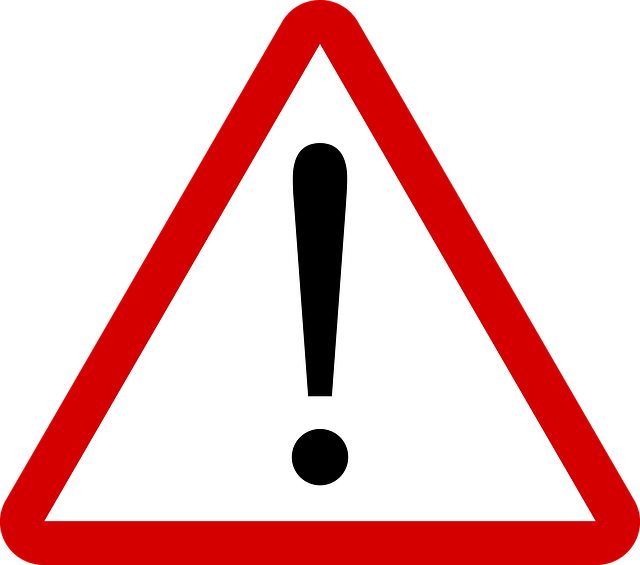 Speculations & Wild Thoughts

- Set Theory & The Observer’s Choice  
  While refining and transcribing this theory, I often listen to the
  music of the Swedish ambient duo **Carbon Based Lifeforms** (could
  there be a more fitting soundtrack?).  
  Among their masterpieces, the vocal sample in *“Set Theory”* — drawn
  from the sci-fi film *Solaris* (2002) — resonates deeply with this
  work: *“There are no answers. Only choices.”*  
  In conjugated carbon computing, there is no absolute, pre-ordained
  direction to information flow: **it is the observer who chooses which
  boundary bonds serve as inputs and which serve as outputs.** The
  calculation is an act of perspective.  
  Furthermore, quantum sets constitute a foundational pillar of this
  entire theoretical framework.  
  A heartfelt thank you to the band for their visionary inspiration!

**[“Carbon Based Lifeforms - Set
Theory”](https://www.youtube.com/watch?v=23iuPKuPd30)**

- From It to Protobit

In 1989, the legendary physicist John Archibald Wheeler coined the
famous doctrine **“It from Bit”**—suggesting that all physical reality
(*it*) emerges from discrete binary questions (*bits*).

Decades later, the quantum computing community expanded this intuition
to **“It from Qubit”**, postulating that spacetime and matter are
knitted from the fabric of quantum entanglement.

Now, I propose taking this lineage one step further: **“It from
Protobit.”**

Crucially, the Protobit is not an ordinary physical component you can
pick apart with tweezers. It is an **emergent, fundamental entity of
information**—akin to the holographic degrees of freedom etched upon the
event horizon of a black hole.

Under the Holographic Principle, all the dimensional physics inside a
(hyper)volume is entirely projected from the information encoded onto
its two-dimensional boundary.

In our model, the 2D network of conjugated carbon bonds acts precisely
as such a holographic surface. The Protobit is the elemental quantum of
information living on this geometric boundary. When we look at a
carbon-carbon bond, we are not merely looking at shared electrons; we
are peering through a subtle crack in the fabric of spacetime, catching
a glimpse of the fundamental informational pixel that projects quantum
reality inward.

Nature did not wait for humans to build computers. Through the resonant
geometry of carbon, the universe reveals that its underlying
architecture has always been holographic—and its fundamental currency
might well be the **Protobit**.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Quantum Set Theory”](../../posts/quantum-set-theory/index.html)**